In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


In [11]:
telecom = pd.read_csv("kenyan_telecom_schema_replica.csv")
mpesa = pd.read_csv("mpesa_schema_replica.csv")
titanic = pd.read_csv("titanic_public_dataset.csv")

tele = telecom.copy()
tit = titanic.copy()

print("Telecom:", tele.shape)
print("M-Pesa:", mpesa.shape)
print("Titanic:", tit.shape)


Telecom: (6000, 13)
M-Pesa: (8000, 13)
Titanic: (891, 12)


In [12]:
def score_model(name, y_test, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    }

def show_confusion(y_test, y_pred, title):
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    plt.figure(figsize=(6,5))
    plt.imshow(confusion_matrix(y_test, y_pred))
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.colorbar()
    plt.show()


## Task 1 — Logistic Regression for Customer Churn


Accuracy: 0.7041666666666667
Precision: 0.12853470437017994
Recall: 0.7575757575757576
F1-score: 0.21978021978021978

Confusion Matrix:
[[795 339]
 [ 16  50]]


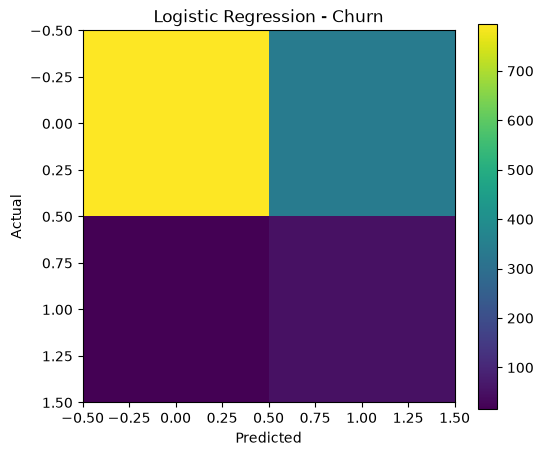

In [13]:
X = tele.drop(columns=["CustomerID", "Churn"])
y = tele["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num = X_train.select_dtypes(include=np.number).columns.tolist()
cat = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

lr_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

r1 = score_model("Logistic Regression - Churn", y_test, y_pred_lr)

print("Accuracy:", r1["Accuracy"])
print("Precision:", r1["Precision"])
print("Recall:", r1["Recall"])
print("F1-score:", r1["F1-score"])

show_confusion(y_test, y_pred_lr, "Logistic Regression - Churn")


## Task 2 — Decision Tree for Titanic Survival


Accuracy: 0.7653631284916201
Precision: 0.7547169811320755
Recall: 0.5797101449275363
F1-score: 0.6557377049180327

Confusion Matrix:
[[97 13]
 [29 40]]


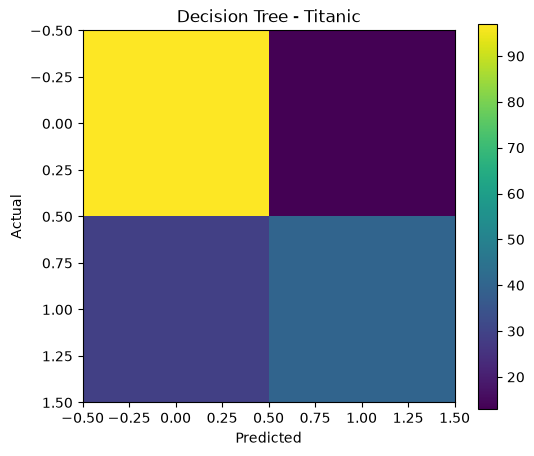

In [14]:
cols = {c.lower(): c for c in tit.columns}

target = cols["survived"]
features = [
    cols[k] for k in
    ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
    if k in cols
]

X = tit[features]
y = tit[target].astype(int)

num = [c for c in features if c.lower() in ["pclass", "age", "sibsp", "parch", "fare"]]
cat = [c for c in features if c not in num]

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

dt_model = Pipeline([
    ("preprocess", preprocess),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

r2 = score_model("Decision Tree - Titanic", y_test, y_pred_dt)

print("Accuracy:", r2["Accuracy"])
print("Precision:", r2["Precision"])
print("Recall:", r2["Recall"])
print("F1-score:", r2["F1-score"])

show_confusion(y_test, y_pred_dt, "Decision Tree - Titanic")


## Task 3 — K-Nearest Neighbours Customer Churn


Accuracy: 0.9441666666666667
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion Matrix:
[[1133    1]
 [  66    0]]


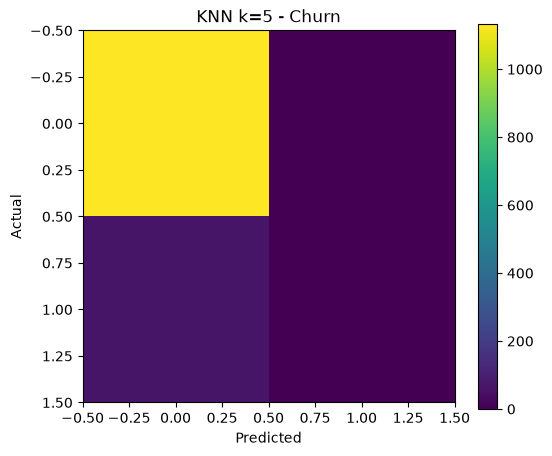

In [15]:
features = [
    "Age",
    "DataUsageGB",
    "CallMinutes",
    "SMSCount",
    "MonthlyCharges",
    "PaymentHistoryScore",
    "TenureMonths"
]

X = tele[features]
y = tele["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean"
    ))
])

knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

r3 = score_model("KNN k=5 - Churn", y_test, y_pred_knn)

print("Accuracy:", r3["Accuracy"])
print("Precision:", r3["Precision"])
print("Recall:", r3["Recall"])
print("F1-score:", r3["F1-score"])

show_confusion(y_test, y_pred_knn, "KNN k=5 - Churn")


## Task 4 — SVM Kernel Comparison on M-Pesa Fraud


SVM Results:
        Model  Accuracy  Precision  Recall  F1-score
0  SVM LINEAR    0.9000        0.0   0.000    0.0000
1    SVM POLY    0.8925        0.2   0.025    0.0444
2     SVM RBF    0.9000        0.0   0.000    0.0000

Best Hyperparameters:
   Kernel                                    Best Parameters
0  linear                                    {'model__C': 1}
1    poly  {'model__C': 1, 'model__degree': 3, 'model__ga...
2     rbf         {'model__C': 0.1, 'model__gamma': 'scale'}


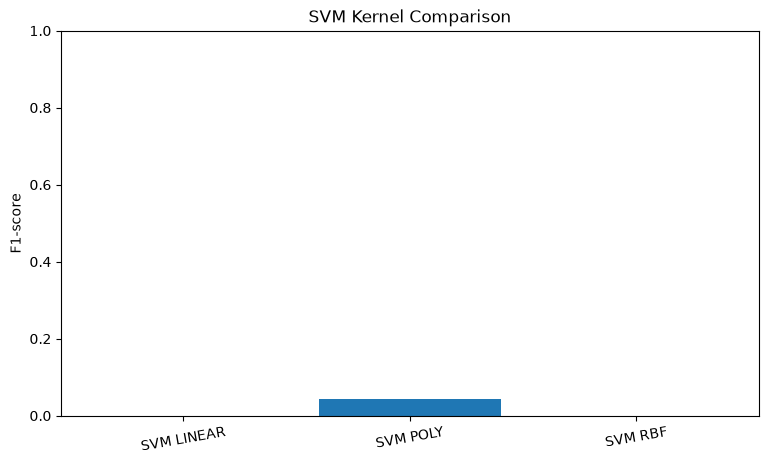

In [16]:
normal_idx = mpesa.index[mpesa["is_fraud"] == 0]
fraud_idx = mpesa.index[mpesa["is_fraud"] == 1]

np.random.seed(42)

sample_idx = np.r_[
    np.random.choice(normal_idx, min(1800, len(normal_idx)), replace=False),
    np.random.choice(fraud_idx, min(200, len(fraud_idx)), replace=False)
]

data = mpesa.loc[sample_idx].sample(frac=1, random_state=42)

num_features = [
    "amount",
    "sender_balance_before",
    "sender_balance_after",
    "receiver_balance_before",
    "receiver_balance_after",
    "hour",
    "month_2026"
]

cat_features = [
    "transaction_type",
    "day_of_week",
    "device_type",
    "region"
]

X = data[num_features + cat_features]
y = data["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

search_spaces = [
    ("linear", {"model__C": [0.1, 1]}),
    ("poly", {"model__C": [0.1, 1], "model__degree": [2, 3], "model__gamma": ["scale"]}),
    ("rbf", {"model__C": [0.1, 1], "model__gamma": ["scale", 0.1]})
]

svm_results = []
svm_best = []

for kernel, grid in search_spaces:
    svm_model = Pipeline([
        ("preprocess", preprocess),
        ("model", SVC(kernel=kernel))
    ])

    grid_model = GridSearchCV(
        svm_model,
        grid,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    grid_model.fit(X_train, y_train)
    y_pred = grid_model.predict(X_test)

    result = score_model("SVM " + kernel.upper(), y_test, y_pred)
    svm_results.append(result)

    svm_best.append({
        "Kernel": kernel,
        "Best Parameters": grid_model.best_params_
    })

svm_results = pd.DataFrame(svm_results)

print("SVM Results:")
print(svm_results.round(4))

print("\nBest Hyperparameters:")
print(pd.DataFrame(svm_best))

plt.figure(figsize=(9,5))
plt.bar(
    svm_results["Model"],
    svm_results["F1-score"]
)
plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("SVM Kernel Comparison")
plt.xticks(rotation=10)
plt.show()


## Task 5 — Decision Tree versus Random Forest


                          Model  Accuracy  Precision  Recall  F1-score
0  Single Decision Tree - Churn    0.9433     0.3333  0.0303    0.0556
1         Random Forest - Churn    0.8217     0.1509  0.4848    0.2302


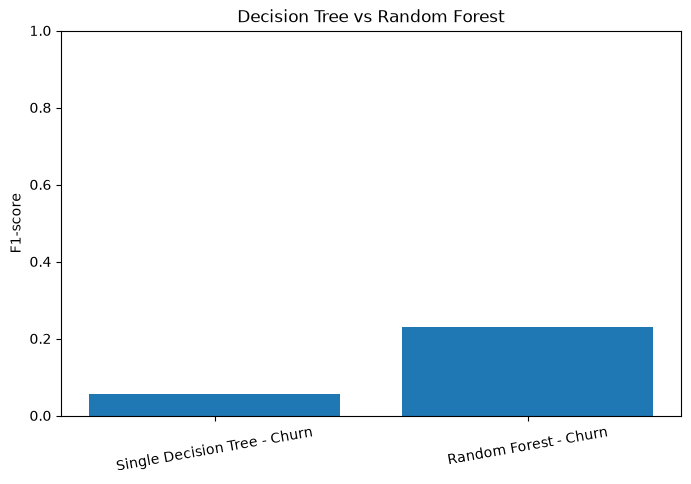

In [17]:
X = tele.drop(columns=["CustomerID", "Churn"])
y = tele["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num = X_train.select_dtypes(include=np.number).columns.tolist()
cat = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

dt_model = Pipeline([
    ("preprocess", preprocess),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

rf_model = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=250,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

r5a = score_model("Single Decision Tree - Churn", y_test, y_pred_dt)
r5b = score_model("Random Forest - Churn", y_test, y_pred_rf)

comparison = pd.DataFrame([r5a, r5b])

print(comparison.round(4))

plt.figure(figsize=(8,5))
plt.bar(
    comparison["Model"],
    comparison["F1-score"]
)
plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("Decision Tree vs Random Forest")
plt.xticks(rotation=10)
plt.show()


## Overall Model Evaluation


Overall Model Results:
                          Model  Accuracy  Precision  Recall  F1-score
0   Logistic Regression - Churn    0.7042     0.1285  0.7576    0.2198
1       Decision Tree - Titanic    0.7654     0.7547  0.5797    0.6557
2               KNN k=5 - Churn    0.9442     0.0000  0.0000    0.0000
3                    SVM LINEAR    0.9000     0.0000  0.0000    0.0000
4                      SVM POLY    0.8925     0.2000  0.0250    0.0444
5                       SVM RBF    0.9000     0.0000  0.0000    0.0000
6  Single Decision Tree - Churn    0.9433     0.3333  0.0303    0.0556
7         Random Forest - Churn    0.8217     0.1509  0.4848    0.2302


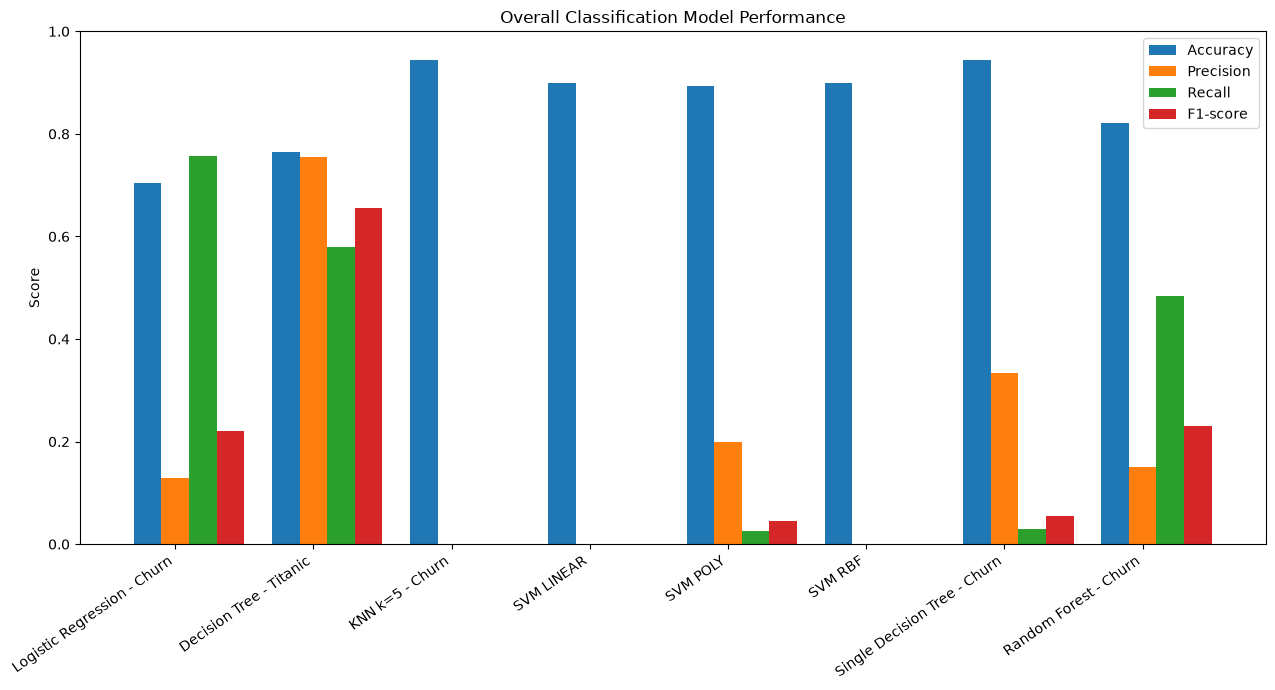

In [18]:
results = pd.DataFrame([
    r1,
    r2,
    r3,
    *svm_results.to_dict("records"),
    r5a,
    r5b
])

print("Overall Model Results:")
print(results.round(4))

results.to_csv("model_results.csv", index=False)

pd.DataFrame(svm_best).to_csv(
    "svm_best_hyperparameters.csv",
    index=False
)

plt.figure(figsize=(13,7))

x = np.arange(len(results))
width = 0.2

plt.bar(x - width, results["Accuracy"], width, label="Accuracy")
plt.bar(x, results["Precision"], width, label="Precision")
plt.bar(x + width, results["Recall"], width, label="Recall")
plt.bar(x + 2 * width, results["F1-score"], width, label="F1-score")

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Overall Classification Model Performance")
plt.xticks(x, results["Model"], rotation=35, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


## 7.1 Model Performance

The final report below compares the two primary models in the reference layout.


In [19]:
import time
from IPython.display import HTML, display

report_X = tele.drop(columns=["CustomerID", "Churn"])
report_y = tele["Churn"]
report_X_train, report_X_test, report_y_train, report_y_test = train_test_split(
    report_X, report_y, test_size=0.2, random_state=42, stratify=report_y
)
report_num = report_X_train.select_dtypes(include=np.number).columns.tolist()
report_cat = report_X_train.select_dtypes(exclude=np.number).columns.tolist()
report_preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), report_num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), report_cat)
])

report_models = {
    "Logistic Regression": Pipeline([
        ("preprocess", report_preprocess),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))
    ]),
    "ID3 Decision Tree": Pipeline([
        ("preprocess", report_preprocess),
        ("model", DecisionTreeClassifier(
            criterion="entropy", max_depth=8, min_samples_split=5,
            min_samples_leaf=2, class_weight="balanced", random_state=42
        ))
    ])
}

report_rows = []
report_matrices = {}
for model_name, model in report_models.items():
    train_started = time.perf_counter()
    model.fit(report_X_train, report_y_train)
    training_time = time.perf_counter() - train_started
    prediction_started = time.perf_counter()
    predictions = model.predict(report_X_test)
    prediction_time = time.perf_counter() - prediction_started
    report_matrices[model_name] = confusion_matrix(report_y_test, predictions)
    report_rows.append({
        "Model": model_name,
        "Train Accuracy": accuracy_score(report_y_train, model.predict(report_X_train)),
        "Test Accuracy": accuracy_score(report_y_test, predictions),
        "Test Precision": precision_score(report_y_test, predictions, zero_division=0),
        "Test Recall": recall_score(report_y_test, predictions, zero_division=0),
        "Test F1": f1_score(report_y_test, predictions, zero_division=0),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

report_table = pd.DataFrame(report_rows)
report_display = report_table.copy()
for metric in ["Train Accuracy", "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]:
    report_display[metric] = report_display[metric].map(lambda value: f"{value:.2%}")
for metric in ["Training Time (s)", "Prediction Time (s)"]:
    report_display[metric] = report_display[metric].map(lambda value: f"{value:.5f} s")
display(HTML(report_display.to_html(index=False, float_format=lambda value: f"{value:.4f}")))

fig = plt.figure(figsize=(12, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], hspace=0.45, wspace=0.35)
for axis, (model_name, matrix) in zip(
    [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])], report_matrices.items()
):
    axis.imshow(matrix, cmap="viridis")
    axis.set_title(model_name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
    axis.set_xticks([0, 1])
    axis.set_yticks([0, 1])
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            axis.text(column, row, matrix[row, column], ha="center", va="center", color="black")

axis = fig.add_subplot(grid[1, :])
metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
x = np.arange(len(report_models))
width = 0.18
for offset, metric, color in zip(np.arange(4) * width - 1.5 * width, metrics, ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    axis.bar(x + offset, report_table[metric], width, label=metric, color=color)
axis.set_title("Model Performance Comparison")
axis.set_ylabel("Score")
axis.set_ylim(0, 1)
axis.set_xticks(x, report_table["Model"])
axis.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout()
plt.show()


AttributeError: The '.style' accessor requires jinja2

## Interpretation

Accuracy shows the overall percentage of correct predictions. Precision shows how many predicted positive cases are actually positive. Recall shows how many actual positive cases are detected. F1-score combines precision and recall.

The SVM comparison shows how different kernels affect the classification result. The Decision Tree is easier to interpret, while Random Forest combines multiple trees to improve the model's generalization.
